# Download **Dataset MC OCR 2021**

In [1]:
import kagglehub
path = kagglehub.dataset_download("domixi1989/vietnamese-receipts-mc-ocr-2021")

Using Colab cache for faster access to the 'vietnamese-receipts-mc-ocr-2021' dataset.


In [2]:
!pip install -q craft-text-detector --no-deps
!pip install -q vietocr --no-deps
!pip install -q gdown einops prefetch_generator albumentations lmdb imgaug
!pip install -q transformers sentencepiece

In [3]:
!pip install -q ninja
!pip install 'git+https://github.com/facebookresearch/detectron2.git' --no-build-isolation

  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-rpnifm5_
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-rpnifm5_
  Resolved https://github.com/facebookresearch/detectron2.git to commit 247691a1c292654867deb35cabb27f18d75a1363
  Preparing metadata (pyproject.toml) ... done


In [4]:
import os, glob, json, time, traceback, warnings
import cv2
import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm
from typing import List, Dict, Any, Tuple, Optional

warnings.filterwarnings("ignore", category=UserWarning)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

OUTPUT_BASE_DIR      = "./pipeline_results"
PREPROCESSED_IMG_DIR = os.path.join(OUTPUT_BASE_DIR, "preprocessed_images")
OCR_JSON_DIR         = os.path.join(OUTPUT_BASE_DIR, "ocr_annotations")
FEATURES_PT_DIR      = os.path.join(OUTPUT_BASE_DIR, "layoutxlm_features")
for d in (PREPROCESSED_IMG_DIR, OCR_JSON_DIR, FEATURES_PT_DIR):
    os.makedirs(d, exist_ok=True)

TARGET_MAX_DIM = 1280     # cạnh dài tối đa sau resize
ENHANCE        = True     # CLAHE + bilateral; thử False nếu VietOCR đọc kém
SAVE_FP16      = True     # lưu feature LayoutXLM ở fp16
OCR_BATCH_SIZE = 32       # số crop mỗi lượt VietOCR
MAX_TOKENS     = 512

print(f"[-] Thiết bị: {DEVICE.upper()}")

[-] Thiết bị: CUDA


#**Stage 0 — Image Preprocessing**

In [5]:
class Stage0Preprocessor:
    """Resize giữ tỉ lệ -> deskew nhẹ -> (tuỳ chọn) CLAHE + bilateral."""

    def __init__(self, target_max_dim: int = 1280, min_skew: float = 0.5,
                 max_skew: float = 15.0, enhance: bool = True):
        self.target_max_dim = target_max_dim
        self.min_skew = min_skew
        self.max_skew = max_skew
        self.enhance = enhance

    def estimate_skew(self, gray: np.ndarray) -> float:
        """Góc (độ, theo quy ước cv2.getRotationMatrix2D) làm các dòng chữ nằm ngang nhất."""
        h, w = gray.shape
        s = 640.0 / max(h, w)
        small = cv2.resize(gray, (max(1, int(w * s)), max(1, int(h * s))),
                           interpolation=cv2.INTER_AREA) if s < 1 else gray
        bw = cv2.threshold(small, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]
        hh, ww = bw.shape
        center = (ww // 2, hh // 2)

        def score(angle: float) -> float:
            M = cv2.getRotationMatrix2D(center, angle, 1.0)
            r = cv2.warpAffine(bw, M, (ww, hh), flags=cv2.INTER_NEAREST)
            prof = r.sum(axis=1, dtype=np.float64)
            return float(np.sum(np.diff(prof) ** 2))   # dòng chữ thẳng -> profile "gắt"

        coarse = np.arange(-self.max_skew, self.max_skew + 1e-6, 1.0)
        best = max(coarse, key=score)
        best = max(np.arange(best - 1.0, best + 1.0 + 1e-6, 0.25), key=score)
        # chỉ xoay khi thực sự cải thiện so với góc 0
        return float(best) if score(best) > 1.05 * score(0.0) else 0.0

    def process(self, image_path: str) -> Tuple[np.ndarray, np.ndarray, float, float]:
        orig = cv2.imread(image_path)
        if orig is None:
            raise FileNotFoundError(f"Không thể đọc file: {image_path}")

        h0, w0 = orig.shape[:2]
        scale = 1.0
        if max(h0, w0) > self.target_max_dim:
            scale = self.target_max_dim / float(max(h0, w0))
            img = cv2.resize(orig, (int(w0 * scale), int(h0 * scale)), interpolation=cv2.INTER_AREA)
        else:
            img = orig.copy()

        angle = 0.0
        a = self.estimate_skew(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY))
        if self.min_skew <= abs(a) <= self.max_skew:
            h, w = img.shape[:2]
            M = cv2.getRotationMatrix2D((w // 2, h // 2), a, 1.0)
            img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_CUBIC,
                                 borderMode=cv2.BORDER_REPLICATE)
            angle = a

        if self.enhance:
            lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
            l, a_, b_ = cv2.split(lab)
            l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
            img = cv2.cvtColor(cv2.merge((l, a_, b_)), cv2.COLOR_LAB2BGR)
            img = cv2.bilateralFilter(img, d=7, sigmaColor=50, sigmaSpace=50)

        return orig, img, scale, angle

# **Stage 1 — CRAFT Text Detection**

In [6]:
import torchvision.models.vgg as vgg
if not hasattr(vgg, "model_urls"):     # tương thích torchvision mới
    vgg.model_urls = {
        'vgg16_bn': 'https://download.pytorch.org/models/vgg16_bn-6c64b313.pth',
        'vgg16': 'https://download.pytorch.org/models/vgg16-397923af.pth',
    }

import craft_text_detector.craft_utils as craft_utils
import craft_text_detector.predict as craft_predict

def _safe_adjust(polys, ratio_w=1, ratio_h=1, ratio_net=2):
    if polys is None or len(polys) == 0:
        return polys
    out = []
    for p in polys:
        if p is None:
            out.append(None)
        else:
            out.append(np.array(p, dtype=np.float32) * (ratio_w * ratio_net, ratio_h * ratio_net))
    return out

_orig_get_det_boxes = craft_utils.getDetBoxes
def _get_det_boxes_no_poly(textmap, linkmap, text_threshold, link_threshold, low_text, poly=False, *a, **k):
    return _orig_get_det_boxes(textmap, linkmap, text_threshold, link_threshold, low_text, False)

for mod in (craft_utils, craft_predict):      # vá ở cả hai nơi vì import có thể khác nhau
    if hasattr(mod, "adjustResultCoordinates"):
        mod.adjustResultCoordinates = _safe_adjust
    if hasattr(mod, "getDetBoxes"):
        mod.getDetBoxes = _get_det_boxes_no_poly

from craft_text_detector import Craft


def sort_reading_order(regions: List[Dict[str, Any]]) -> List[Dict[str, Any]]:
    """Gom theo dòng (theo tâm y, ngưỡng = 0.5 * chiều cao trung vị), mỗi dòng sắp trái -> phải."""
    if not regions:
        return regions
    med_h = float(np.median([r["bbox"][3] - r["bbox"][1] for r in regions]))
    thr = max(4.0, 0.5 * med_h)
    cy = lambda r: (r["bbox"][1] + r["bbox"][3]) / 2.0
    lines: List[Dict[str, Any]] = []
    for r in sorted(regions, key=cy):
        if lines and abs(cy(r) - lines[-1]["cy"]) <= thr:
            ln = lines[-1]
            ln["items"].append(r)
            ln["cy"] = float(np.mean([cy(x) for x in ln["items"]]))
        else:
            lines.append({"cy": cy(r), "items": [r]})
    ordered = []
    for ln in lines:
        ordered.extend(sorted(ln["items"], key=lambda r: r["bbox"][0]))
    return ordered


def drop_nested(regions: List[Dict[str, Any]], thr: float = 0.8) -> List[Dict[str, Any]]:
    """Bỏ box nằm (>= thr diện tích) trong một box lớn hơn, ví dụ box riêng cho dấu phẩy của '27,000'."""
    areas = [max(1, (r["bbox"][2] - r["bbox"][0]) * (r["bbox"][3] - r["bbox"][1])) for r in regions]
    keep = []
    for i, r in enumerate(regions):
        x0, y0, x1, y1 = r["bbox"]
        nested = False
        for j, o in enumerate(regions):
            if i == j or areas[j] < areas[i] or (areas[j] == areas[i] and j > i):
                continue
            iw = min(x1, o["bbox"][2]) - max(x0, o["bbox"][0])
            ih = min(y1, o["bbox"][3]) - max(y0, o["bbox"][1])
            if iw > 0 and ih > 0 and (iw * ih) / areas[i] >= thr:
                nested = True
                break
        if not nested:
            keep.append(r)
    return keep


class Stage1CraftDetector:
    def __init__(self, device: Optional[str] = None, long_size: int = 1280):
        self.device = device or DEVICE
        base = dict(output_dir=None, cuda=(self.device == "cuda"),
                    text_threshold=0.7, link_threshold=0.4, low_text=0.4)
        try:   # không nạp refine-net; long_size khớp với ảnh đã resize ở Stage 0
            self.detector = Craft(**base, refiner=False, long_size=long_size, export_extra=False)
        except TypeError:   # bản thư viện khác tên tham số
            self.detector = Craft(**base, crop_type=None)
            if hasattr(self.detector, "refine_net"):
                self.detector.refine_net = None

    def detect(self, image_bgr: np.ndarray, scale_ratio: float = 1.0) -> List[Dict[str, Any]]:
        h_img, w_img = image_bgr.shape[:2]
        prediction = self.detector.detect_text(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
        raw_boxes = prediction.get("boxes", [])
        if raw_boxes is None or len(raw_boxes) == 0:
            return []

        regions = []
        for box in raw_boxes:
            pts = np.asarray(box, dtype=np.float32)
            if pts.ndim != 2 or pts.shape[0] < 3 or pts.shape[1] != 2:
                continue
            x0 = int(max(0, np.floor(pts[:, 0].min())))
            y0 = int(max(0, np.floor(pts[:, 1].min())))
            x1 = int(min(w_img, np.ceil(pts[:, 0].max())))
            y1 = int(min(h_img, np.ceil(pts[:, 1].max())))
            if (x1 - x0) < 3 or (y1 - y0) < 3:
                continue
            regions.append({
                "polygon": pts.astype(int).tolist(),
                "bbox": [x0, y0, x1, y1],
                "orig_bbox": [int(v / scale_ratio) for v in (x0, y0, x1, y1)],  # chỉ chính xác khi skew_angle = 0
            })
        return sort_reading_order(drop_nested(regions))

# **Stage 2 — VietOCR Text Recognition**

In [7]:
from vietocr.tool.predictor import Predictor
from vietocr.tool.config import Cfg

class Stage2VietOcrRecognizer:
    def __init__(self, device: Optional[str] = None, batch_size: int = 32):
        self.device = device or DEVICE
        self.batch_size = batch_size
        config = Cfg.load_config_from_name('vgg_transformer')
        config['device'] = self.device
        config['predictor']['beamsearch'] = False
        self.predictor = Predictor(config)
        self.n_errors = 0

    def _predict(self, crops: List[Image.Image]):
        try:   # nhanh: theo batch
            texts, probs = self.predictor.predict_batch(crops, return_prob=True)
            return list(texts), [float(p) for p in probs]
        except Exception:   # dự phòng: từng crop
            texts, probs = [], []
            for c in crops:
                try:
                    t, p = self.predictor.predict(c, return_prob=True)
                except Exception:
                    self.n_errors += 1
                    t, p = "", 0.0
                texts.append(t); probs.append(float(p))
            return texts, probs

    def recognize(self, image_bgr: np.ndarray, regions: List[Dict[str, Any]]) -> List[Dict[str, Any]]:
        h_img, w_img = image_bgr.shape[:2]
        rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        crops, kept = [], []
        for item in regions:
            x0, y0, x1, y1 = item["bbox"]
            x0, y0 = max(0, x0 - 3), max(0, y0 - 2)
            x1, y1 = min(w_img, x1 + 3), min(h_img, y1 + 2)
            if (x1 - x0) < 4 or (y1 - y0) < 4:
                continue
            crops.append(Image.fromarray(rgb[y0:y1, x0:x1]))
            kept.append(item)

        results = []
        for i in range(0, len(crops), self.batch_size):
            texts, probs = self._predict(crops[i:i + self.batch_size])
            for item, t, p in zip(kept[i:i + self.batch_size], texts, probs):
                t = (t or "").strip()
                if t:
                    e = dict(item); e["text"] = t; e["ocr_confidence"] = p
                    results.append(e)
        return results

# **Stage 3 — LayoutXLM Feature Extraction**

In [8]:
from transformers import AutoProcessor, AutoModel

def split_box_by_tokens(box: List[int], tokens: List[str]) -> List[List[int]]:
    """Chia bbox ngang cho từng từ, tỉ lệ theo độ dài từ (tính cả khoảng trắng)."""
    total_w = max(1, box[2] - box[0])
    total_chars = sum(len(t) for t in tokens) + (len(tokens) - 1)
    out, cursor = [], float(box[0])
    for t in tokens:
        w = total_w * len(t) / total_chars
        out.append([int(cursor), box[1], int(round(cursor + w)), box[3]])
        cursor += w + total_w / total_chars
    return out


class Stage3LayoutXLMExtractor:
    def __init__(self, model_name: str = "microsoft/layoutxlm-base", device: Optional[str] = None,
                 max_tokens: int = 512, save_fp16: bool = True):
        self.device = device or DEVICE
        self.max_tokens = max_tokens
        self.save_fp16 = save_fp16
        self.processor = AutoProcessor.from_pretrained(model_name, apply_ocr=False)
        self.model = AutoModel.from_pretrained(model_name).to(self.device).eval()

    @staticmethod
    def normalize_bbox(bbox, width, height):
        x0 = int(np.clip(1000 * bbox[0] / width, 0, 1000)); y0 = int(np.clip(1000 * bbox[1] / height, 0, 1000))
        x1 = int(np.clip(1000 * bbox[2] / width, 0, 1000)); y1 = int(np.clip(1000 * bbox[3] / height, 0, 1000))
        return [min(x0, x1), min(y0, y1), max(x0, x1), max(y0, y1)]

    def extract(self, image_pil: Image.Image, ocr_results: List[Dict[str, Any]]) -> Dict[str, Any]:
        w, h = image_pil.size
        words, word_boxes = [], []
        for item in ocr_results:
            tokens = item.get("text", "").split()
            if not tokens:
                continue
            for tok, b in zip(tokens, split_box_by_tokens(item["bbox"], tokens)):
                words.append(tok)
                word_boxes.append(self.normalize_bbox(b, w, h))
        if not words:
            return {"last_hidden_state": None}

        words, word_boxes = words[:self.max_tokens - 2], word_boxes[:self.max_tokens - 2]
        enc = self.processor(images=image_pil, text=words, boxes=word_boxes, return_tensors="pt",
                             truncation=True, padding="max_length", max_length=self.max_tokens)

        inputs = dict(input_ids=enc["input_ids"], bbox=enc["bbox"], attention_mask=enc["attention_mask"])
        image_tensor = enc.get("image", enc.get("pixel_values"))
        inputs = {k: v.to(self.device) for k, v in inputs.items()}
        if image_tensor is not None:
            inputs["image"] = image_tensor.to(self.device)

        with torch.inference_mode():
            out = self.model(**inputs, output_hidden_states=False)

        hs = out.last_hidden_state.cpu()
        if self.save_fp16:
            hs = hs.half()
        n_tokens = int(enc["attention_mask"].sum())
        return {
            "last_hidden_state": hs,
            "input_ids": enc["input_ids"],
            "normalized_bboxes": enc["bbox"],
            "attention_mask": enc["attention_mask"],
            "words": words,
            "possibly_truncated": n_tokens >= self.max_tokens,
        }

# **INTEGRATION TEST**

In [9]:
print("[-] Đang nạp các model...")
stage0 = Stage0Preprocessor(target_max_dim=TARGET_MAX_DIM, enhance=ENHANCE)
stage1 = Stage1CraftDetector(device=DEVICE, long_size=TARGET_MAX_DIM)
stage2 = Stage2VietOcrRecognizer(device=DEVICE, batch_size=OCR_BATCH_SIZE)
stage3 = Stage3LayoutXLMExtractor(device=DEVICE, max_tokens=MAX_TOKENS, save_fp16=SAVE_FP16)

def locate_images():
    base = path if "path" in globals() else "/root/.cache/kagglehub/datasets"
    imgs = []
    for ext in ("jpg", "JPG", "jpeg", "png"):
        imgs += glob.glob(os.path.join(base, "**", f"*.{ext}"), recursive=True)
    only = [p for p in imgs if "data0.7" in p]
    return sorted(only if only else imgs)

images_to_process = locate_images()
print(f"[+] Tổng số ảnh: {len(images_to_process)}")


def _paths(file_id):
    return (os.path.join(OCR_JSON_DIR, f"{file_id}.json"),
            os.path.join(FEATURES_PT_DIR, f"{file_id}.pt"),
            os.path.join(PREPROCESSED_IMG_DIR, f"{file_id}.jpg"))

def is_done(file_id) -> bool:
    j, pt, _ = _paths(file_id)
    if not os.path.exists(j):
        return False
    if os.path.exists(pt):
        return True
    try:   # ảnh không có chữ: có JSON nhưng không có .pt vẫn là hoàn tất
        with open(j, encoding="utf-8") as f:
            meta = json.load(f)
        return meta.get("n_text_regions", meta.get("total_words", -1)) == 0
    except Exception:
        return False


def process_one(img_path: str, file_id: str) -> Dict[str, Any]:
    json_path, pt_path, img_out = _paths(file_id)

    orig_img, pre, scale, angle = stage0.process(img_path)
    cv2.imwrite(img_out, pre, [cv2.IMWRITE_JPEG_QUALITY, 95])
    h_proc, w_proc = pre.shape[:2]

    detected = stage1.detect(pre, scale_ratio=scale)
    ocr_items = stage2.recognize(pre, detected) if detected else []

    meta = {
        "file_id": file_id,
        "orig_shape": list(orig_img.shape[:2]),
        "processed_shape": [h_proc, w_proc, 3],
        "scale_factor": float(scale),
        "skew_angle": float(angle),
        "n_detected": len(detected),
        "n_text_regions": len(ocr_items),
        "ocr_items": ocr_items,
    }
    features = None
    if ocr_items:
        pil = Image.fromarray(cv2.cvtColor(pre, cv2.COLOR_BGR2RGB))
        features = stage3.extract(pil, ocr_items)
        meta["possibly_truncated"] = bool(features.get("possibly_truncated", False))

    # ghi .pt trước, JSON sau cùng: JSON xuất hiện = ảnh đã xong (checkpoint đáng tin)
    if features is not None and features["last_hidden_state"] is not None:
        tmp = pt_path + ".tmp"
        torch.save({"file_id": file_id,
                    "last_hidden_state": features["last_hidden_state"],
                    "input_ids": features["input_ids"],
                    "normalized_bboxes": features["normalized_bboxes"],
                    "attention_mask": features["attention_mask"],
                    "words": features["words"]}, tmp)
        os.replace(tmp, pt_path)
    tmp = json_path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False)
    os.replace(tmp, json_path)
    return {"detected": len(detected), "ocr": len(ocr_items)}


def run_pipeline(paths: List[str], abort_after: int = 20, abort_fail_ratio: float = 0.5,
                 show_errors: int = 3):
    stats = {"ok": 0, "empty": 0, "skipped": 0, "failed": 0}
    failed: List[Tuple[str, str]] = []
    t0 = time.time()
    pbar = tqdm(paths, desc="Đang xử lý")
    for i, p in enumerate(pbar):
        file_id = os.path.splitext(os.path.basename(p))[0]
        if is_done(file_id):
            stats["skipped"] += 1
            continue
        try:
            r = process_one(p, file_id)
            stats["ok" if r["ocr"] > 0 else "empty"] += 1
        except Exception:
            tb = traceback.format_exc()
            failed.append((file_id, tb))
            stats["failed"] += 1
            if len(failed) <= show_errors:
                tqdm.write(f"[!] {file_id}\n{tb}")

        tried = stats["ok"] + stats["empty"] + stats["failed"]
        if tried >= abort_after and stats["failed"] / tried > abort_fail_ratio:
            tqdm.write(f"[x] Dừng sớm: {stats['failed']}/{tried} ảnh lỗi. Sửa lỗi ở trên rồi chạy lại.")
            break
        pbar.set_postfix(stats)
        if (i + 1) % 50 == 0 and torch.cuda.is_available():
            torch.cuda.empty_cache()

    if failed:
        with open(os.path.join(OUTPUT_BASE_DIR, "failed.json"), "w", encoding="utf-8") as f:
            json.dump([{"file_id": a, "traceback": b} for a, b in failed], f, ensure_ascii=False, indent=1)
    print(f"\n[✓] {stats}  |  {time.time() - t0:.0f}s  |  lỗi VietOCR từng crop: {stage2.n_errors}")
    if failed:
        print(f"    Chi tiết {len(failed)} lỗi: {OUTPUT_BASE_DIR}/failed.json")
    return stats, failed

[-] Đang nạp các model...
Model weight /tmp/vgg_transformer.pth exsits. Ignore download!


Loading weights:   0%|          | 0/744 [00:00<?, ?it/s]

[transformers] LayoutLMv2Model LOAD REPORT from: microsoft/layoutxlm-base
Key                                                                                   | Status     |  | 
--------------------------------------------------------------------------------------+------------+--+-
layoutlmv2.visual.backbone.bottom_up.res4.{0...22}.conv1.norm.num_batches_tracked     | UNEXPECTED |  | 
layoutlmv2.visual.backbone.bottom_up.res4.{0...22}.conv3.norm.num_batches_tracked     | UNEXPECTED |  | 
layoutlmv2.visual.backbone.bottom_up.res4.{0...22}.conv2.norm.num_batches_tracked     | UNEXPECTED |  | 
layoutlmv2.visual.backbone.bottom_up.res2.{0, 1, 2}.conv2.norm.num_batches_tracked    | UNEXPECTED |  | 
layoutlmv2.visual.backbone.bottom_up.res2.{0, 1, 2}.conv3.norm.num_batches_tracked    | UNEXPECTED |  | 
layoutlmv2.visual.backbone.bottom_up.res3.{0, 1, 2, 3}.conv2.norm.num_batches_tracked | UNEXPECTED |  | 
layoutlmv2.visual.backbone.bottom_up.res3.{0, 1, 2, 3}.conv1.norm.num_batches_tracked 

[+] Tổng số ảnh: 1044


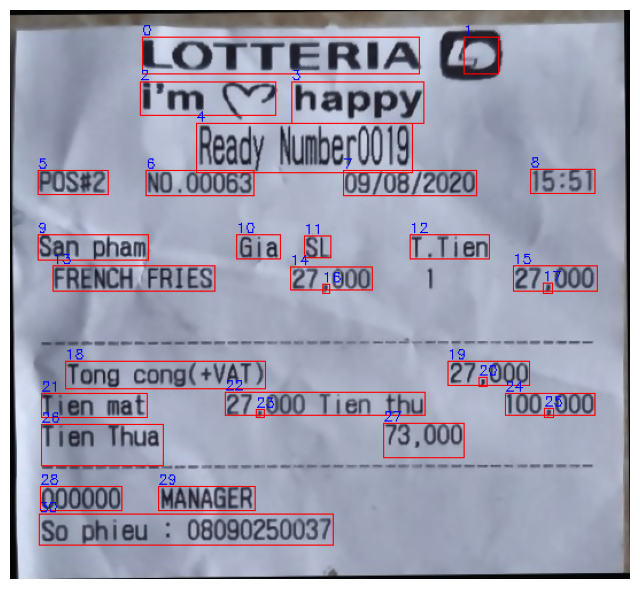

skew=nan°  regions=31  truncated=None
  0  0.93  LOTTERIA
  1  0.70  9
  2  0.66  im
  3  0.93  happy
  4  0.93  Ready Number0019
  5  0.89  POS42
  6  0.89  NO.00063
  7  0.93  09/08/2020
  8  0.93  15:51
  9  0.93  San pham
 10  0.93  Gia
 11  0.93  SL
 12  0.93  T.Tien
 13  0.88  FRENCH FRIES
 14  0.93  27,000
 15  0.93  27,000
 16  0.82  9
 17  0.17  D
 18  0.82  Tong cong((-VAT)
 19  0.93  27,000
 20  0.85  2
 21  0.93  Tien mat
 22  0.93  27,000 Tien thu
 23  0.94  2
 24  0.93  100,000
 25  0.17  5
 26  0.93  Tien Thua
 27  0.93  73,000
 28  0.93  000000
 29  0.93  MANAGER
 30  0.93  So phieu: 08090250037


In [10]:
import matplotlib.pyplot as plt

def visualize(file_id: str):
    json_path, pt_path, img_path = _paths(file_id)
    meta = json.load(open(json_path, encoding="utf-8"))
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    for k, it in enumerate(meta["ocr_items"]):
        x0, y0, x1, y1 = it["bbox"]
        cv2.rectangle(img, (x0, y0), (x1, y1), (255, 0, 0), 1)
        cv2.putText(img, str(k), (x0, max(10, y0 - 2)), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 255), 1)
    plt.figure(figsize=(8, 12)); plt.imshow(img); plt.axis("off"); plt.show()
    print(f"skew={meta.get('skew_angle', float('nan')):.2f}°  "
          f"regions={meta.get('n_text_regions', meta.get('total_words'))}  truncated={meta.get('possibly_truncated')}")
    for k, it in enumerate(meta["ocr_items"][:40]):
        print(f"{k:>3}  {it['ocr_confidence']:.2f}  {it['text']}")

ids = [os.path.splitext(os.path.basename(p))[0] for p in images_to_process]
visualize(next(i for i in ids if os.path.exists(_paths(i)[1])))